# FPT — Gap mở cửa và thân nến có giúp model không?

## Câu hỏi và cách đọc
**A:** 6 feature hiện tại. **B:** thay `Log_Return` bằng `Gap_Log` và `Body_Log` → 7 feature. Chỉ dữ liệu FPT, cùng ngày/nhãn/fold/cấu hình model. Giữ cả kết quả tốt và xấu; không mặc định B tốt hơn.

Xem phần 1 để hiểu feature, phần 2–3 xem thay đổi metric và khoảng bất định, phần 4 xem giá dự báo/thực tế, phần 5–6 xem hướng/xác suất và selective. Notebook đọc kết quả đã lưu, **không train hoặc tải giá**. Toàn bộ giai đoạn2022–2026 đã được xem, là nghiên cứu hồi cứu thích nghi, chưa chứng minh lợi thế forward.

**Kết quả lượt này: chưa đủ căn cứ thay A.** Mean-fold RMSE 2022–2024 của Ridge_recent tăng 0,0162190 → 0,0162930 (cao hơn 0,46%). Logistic raw balanced tăng rất ít, 51,83% → 51,92% (+0,09 điểm %), CI từng fold vẫn chứa 0. Trên 2026, Ridge_recent B có RMSE cao hơn A 1,44%, Hit nonzero giảm 50,76% → 44,67%.

Giữ cả năm 2025 mà B có điểm RMSE tốt hơn, cùng các năm kém hơn. Không chọn riêng 2025 để tuyên bố cải thiện toàn bộ. Chưa promote feature/model.

## Phương pháp và giới hạn
- Gap tại origin t = log(Open_t / Close_previous_eligible); body = log(Close_t / Open_t). Cộng lại bằng Log_Return_t. **Chờ phiên t đóng cửa**, dùng feature đó đoán quan sát giao dịch tiếp theo. Không dùng Open của phiên cần đoán.
- Previous eligible đúng chuỗi positive-volume/valid-candle của pipeline cũ; không mặc định ngày lịch liền trước, không fill. Giá cùng basis adjusted Vietcap; chưa chứng nhận point-in-time hay lịch sàn.
- Ridge_shared và Logistic học cùng các dòng nonzero đến30/6 năm trước; Q3 sigmoid, Q4 chọn margin; evaluation năm sau. Ridge_recent train cả window3y đến cuối năm trước (gồm return0), cùng cutoff A/B, là đối chứng giá gần hơn.
- Hyperparameters/seed/threshold grid không đổi. A tái dùng artifact cũ, B train mới. A/B trong từng strategy cùng mọi phase; không chọn feature bằng evaluation. Chọn A/B từ validation chỉ cho Ridge_shared và Logistic_raw; không dùng validation đã nằm trong training của Ridge_recent.
- Classifier không có giá dự báo. Actual0 giữ trong evaluation; call vào actual0 tính sai, abstain không được tính đúng đứng giá. Hit nonzero, accuracy mọi calls và coverage khác nhau.
- Alpha/C giữ cố định nhưng đổi cơ sở feature và scaling có thể đổi regularization hiệu dụng; chênh điểm không chứng minh tác động nhân quả của gap/body. Đọc cả các fold và CI, không chọn một tháng đẹp.

## Dữ liệu và tham số
Đổi `VIEW_MONTH` để phóng to một tháng2026, rồi Run all. Bảng/chart gộp vẫn giữ cả giai đoạn. Cần numpy/pandas/matplotlib/IPython và thư mục study; không cần weights. Trên Colab cần tải cả thư mục kết quả và đặt `DATA_DIR` nếu không chạy từ repo. Outputs đã lưu để xem ngay.

In [1]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
VIEW_MONTH='2026-10'
DATA_DIR=None
STUDY_ID='20261030T093521684942Z'
if DATA_DIR is None:
    DATA_DIR=next((p/'reports/candle_ablation'/STUDY_ID for p in [Path.cwd(),*Path.cwd().parents]
                   if (p/'reports/candle_ablation'/STUDY_ID/'metrics.csv').exists()),None)
if DATA_DIR is None:raise FileNotFoundError('Đặt DATA_DIR tới thư mục kết quả candle_ablation của study.')
DATA_DIR=Path(DATA_DIR)
EXPECTED_SHA256={'protocol.json': '343935d61e30cb34f6becebb94c6c3e8c25925de574604a532e2213c65b874e6', 'verification.json': '13b22f67633c175260f5806ca6b8e0fa981ee628607fca40d6ebc17657c24147', 'metrics.csv': 'ebe8b82625887132ed5ec4b53062072278d2b4a314dcc11ad5ed7c0a77129bbd', 'predictions.csv.gz': 'dc36fb98bb2c5e09c2bb045368374b0b6c5e13dc615cc7216e4c769f828ab96f', 'feature_label_snapshot.csv.gz': 'c50006fc450f9998dcc6e7e643904c55b21e6b7249bf668ef0175d560f247fd3', 'primary_summary.csv': 'f155244bc001ed764d915d7dea43e3b456019b613bb43aa6210877d4e07595cc', 'paired_effects.csv': '887e8f329fe4cd3c7a92f583b08ea8605fae66aca187fa354e08ffd318fdbf24', 'validation_scores.csv': '36e4006d6ffa1fb62c3c799d8360e167124262679b61ee47c65e0ec6d92fdf23', 'feature_selection.csv': '2bcd6dad3c7213905c7bb9217b1605edef04d414c379e8afb03f39ba9ff5d204', 'validation_selected_evaluation.csv': '6707717a362cca42af97b7b9ac746cffeb2d5832279041c2367da22d428bc018', 'threshold_selection.csv': 'a7771fb062e50c511192ba205fb4106d55f3eb07b5a142665663c211ee2c53a2', 'jun_oct_metrics.csv': '7225073bac83653562afc05e4cf8f9ea3a1aa9ae420e79be9d3a466eceb53d59'}
for f,sha in EXPECTED_SHA256.items():assert hashlib.sha256((DATA_DIR/f).read_bytes()).hexdigest()==sha,f
read=lambda f:pd.read_csv(DATA_DIR/f)
metrics=read('metrics.csv');primary=read('primary_summary.csv');effects=read('paired_effects.csv')
pred=read('predictions.csv.gz');feature=read('feature_label_snapshot.csv.gz')
for frame in [pred,feature]:
    frame['Date']=pd.to_datetime(frame.Date);frame['Target_Date_1d']=pd.to_datetime(frame.Target_Date_1d)
selection=read('feature_selection.csv');selected=read('validation_selected_evaluation.csv');thresholds=read('threshold_selection.csv')
validation=read('validation_scores.csv');june_oct=read('jun_oct_metrics.csv')
verification=json.loads((DATA_DIR/'verification.json').read_text())
assert np.allclose(feature.Gap_Log+feature.Body_Log,feature.Log_Return,atol=1e-12)
ev=pred[pred.phase=='evaluation'].copy()
for (fold,strategy),group in ev.groupby(['fold','strategy']):
    a=group[group.case=='A_returns6'];b=group[group.case=='B_gap_body7']
    assert list(zip(a.Date,a.Target_Date_1d))==list(zip(b.Date,b.Target_Date_1d))
    assert np.allclose(a.actual_log_return,b.actual_log_return)
    for case,g in group.groupby('case'):
        saved=metrics[(metrics.fold==fold)&(metrics.strategy==strategy)&(metrics.case==case)].iloc[0]
        calls=g.direction.ne(0);correct=calls&(g.direction==np.sign(g.actual_log_return))
        assert len(g)==saved.n and calls.sum()==saved.calls_n and correct.sum()==saved.correct_n
        if g.predicted_log_return.notna().all():
            assert np.isclose(np.sqrt(np.mean((g.predicted_log_return-g.actual_log_return)**2)),saved.return_rmse)
assert VIEW_MONTH in ev[ev.year==2026].Target_Date_1d.dt.strftime('%Y-%m').unique()
QA=Path.cwd()/'.cache/candle-notebook-qa';QA.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(12,4.5),'font.size':11,'axes.grid':True,'grid.alpha':.18})
COLORS={'A_returns6':'#1674a5','B_gap_body7':'#277c62'}
def show(name):
    plt.tight_layout();plt.savefig(QA/(name+'.png'),dpi=140,bbox_inches='tight');plt.show()
def table(frame):display(frame.style.format(precision=3,na_rep='—'))
display(Markdown(f"Study **{STUDY_ID}** · {verification['artifacts_reloaded']} artifacts reload · {verification['A_control_prediction_rows_matched']} forecast rows A khớp control · không train trong notebook."))

Study **20261030T093521684942Z** · 40 artifacts reload · 5975 forecast rows A khớp control · không train trong notebook.

## 1. Gap và thân nến — cùng origin, không phải target tương lai
Các cột dưới tính bằng log-return ×100 (% log-return), không phải simple return. Đường đen là tổng current log-return, không phải return phiên kế tiếp. Bảng giữ Open/Previous Close để có thể kiểm tra công thức.

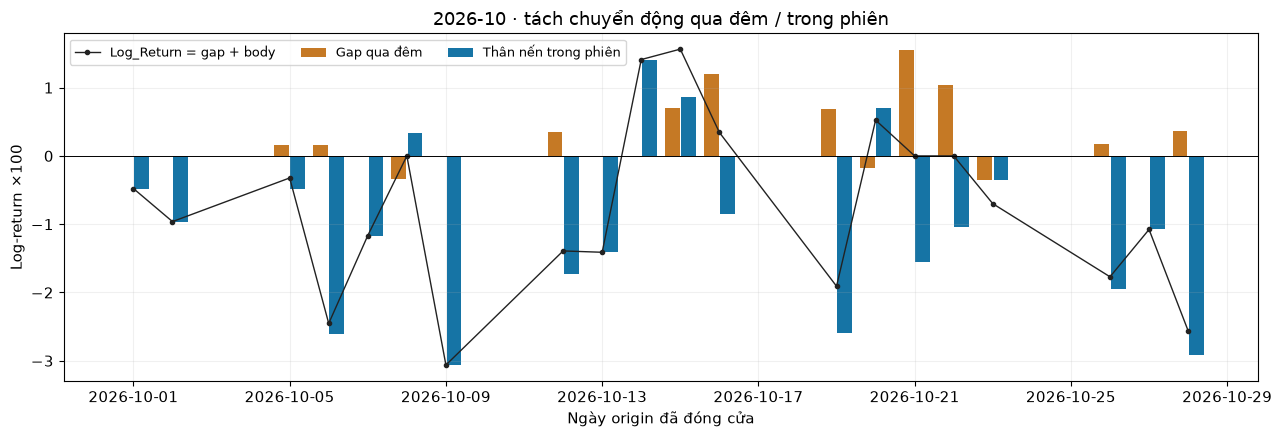

,Date,Open,Previous_Eligible_Date,Previous_Eligible_Close,Close,Gap_Log,Body_Log,Log_Return
2130,2026-10-01 00:00:00,63000.000,2026-09-30,63000.000,62700.000,0.000,-0.005,-0.005
2131,2026-10-02 00:00:00,62700.000,2026-10-01,62700.000,62100.000,0.000,-0.010,-0.010
2132,2026-10-05 00:00:00,62200.000,2026-10-02,62100.000,61900.000,0.002,-0.005,-0.003
2133,2026-10-06 00:00:00,62000.000,2026-10-05,61900.000,60400.000,0.002,-0.026,-0.025
2134,2026-10-07 00:00:00,60400.000,2026-10-06,60400.000,59700.000,0.000,-0.012,-0.012
2135,2026-10-08 00:00:00,59500.000,2026-10-07,59700.000,59700.000,-0.003,0.003,0.000
2136,2026-10-09 00:00:00,59700.000,2026-10-08,59700.000,57900.000,0.000,-0.031,-0.031
2137,2026-10-12 00:00:00,58100.000,2026-10-09,57900.000,57100.000,0.003,-0.017,-0.014


Sai khác identity lớn nhất trên toàn dữ liệu: **4.00e-16**. Dữ liệu canonical không thay đổi.

In [2]:
g=feature[feature.Date.dt.strftime('%Y-%m')==VIEW_MONTH].copy()
fig,ax=plt.subplots(figsize=(13,4.5))
ax.bar(g.Date-pd.Timedelta(hours=5),100*g.Gap_Log,width=.38,color='#c57925',label='Gap qua đêm')
ax.bar(g.Date+pd.Timedelta(hours=5),100*g.Body_Log,width=.38,color='#1674a5',label='Thân nến trong phiên')
ax.plot(g.Date,100*g.Log_Return,'o-',ms=3,color='#222',lw=1,label='Log_Return = gap + body')
ax.axhline(0,color='black',lw=.7);ax.set_xlabel('Ngày origin đã đóng cửa');ax.set_ylabel('Log-return ×100')
ax.set_title(VIEW_MONTH+' · tách chuyển động qua đêm / trong phiên');ax.legend(ncol=3,fontsize=9)
show('01_gap_body')
table(g[['Date','Open','Previous_Eligible_Date','Previous_Eligible_Close','Close','Gap_Log','Body_Log','Log_Return']].head(8))
display(Markdown(f"Sai khác identity lớn nhất trên toàn dữ liệu: **{abs(feature.Gap_Log+feature.Body_Log-feature.Log_Return).max():.2e}**. Dữ liệu canonical không thay đổi."))

## 2. Sai số Ridge: B có tốt hơn A không?
Điểm dương là RMSE của B thấp hơn A: `100 × (1 − RMSE_B/RMSE_A)`. Khoảng95% mô tả dùng paired block-bootstrap10 origin/2.000 resamples, seed cố định; không xử lý hết adaptive research/multiple testing. 2025/2026 là diagnostic, không chọn cấu hình bằng các điểm này.

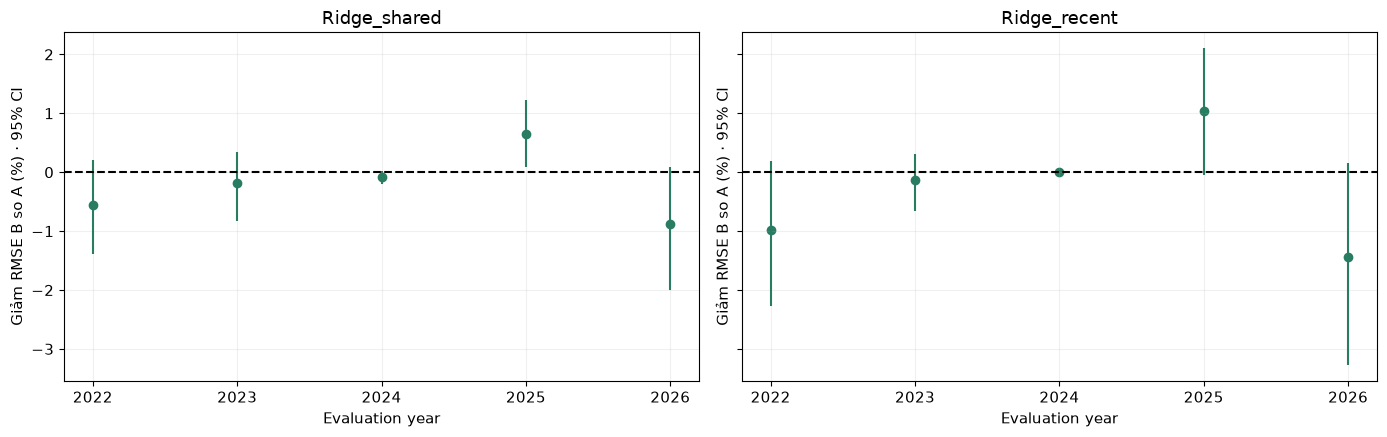

,,mean_fold_return_rmse,worst_fold_return_rmse,mean_fold_balanced
strategy,case,,,
Ridge_recent,A_returns6,0.016,0.021,52.300
Ridge_shared,A_returns6,0.016,0.021,53.356
Ridge_recent,B_gap_body7,0.016,0.021,52.330
Ridge_shared,B_gap_body7,0.016,0.021,52.467


In [3]:
fig,axes=plt.subplots(1,2,figsize=(14,4.5),sharey=True)
for ax,strategy in zip(axes,['Ridge_shared','Ridge_recent']):
    g=effects[effects.strategy==strategy].sort_values('year');x=g.year.to_numpy()
    ax.vlines(x,g.rmse_gain_pct_ci_low,g.rmse_gain_pct_ci_high,color='#277c62');ax.scatter(x,g.rmse_gain_pct,color='#277c62')
    ax.axhline(0,color='black',ls='--');ax.set_xticks(x);ax.set_title(strategy);ax.set_xlabel('Evaluation year');ax.set_ylabel('Giảm RMSE B so A (%) · 95% CI')
show('02_ridge_rmse_gain')
table(primary[primary.strategy.str.startswith('Ridge')].set_index(['strategy','case'])[['mean_fold_return_rmse','worst_fold_return_rmse','mean_fold_balanced']])

## 3. Đoán hướng và lựa chọn bằng validation
Balanced change là B−A, đơn vị điểm phần trăm; dương tốt hơn. Chỉ so forced methods có cùng mẫu. Selective có thể giữ ngày khác nhau nên không gán cùng một CI cải thiện. Bảng lựa chọn A/B lấy từ validation, không từ evaluation.

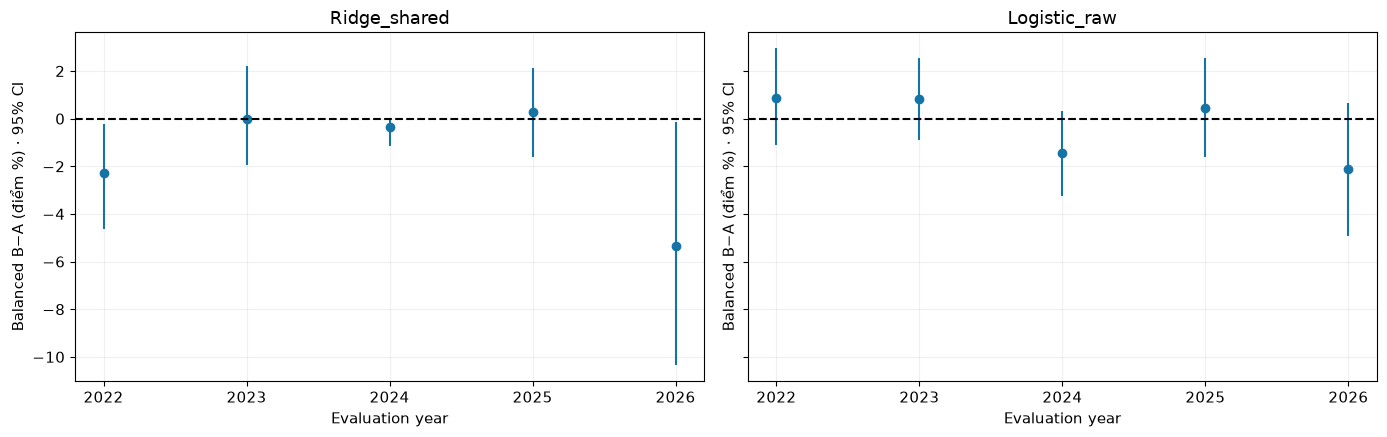

,,mean_fold_balanced,mean_fold_hit_nonzero,mean_fold_coverage
strategy,case,,,
Logistic_raw,A_returns6,51.833,55.006,100.000
Ridge_shared,A_returns6,53.356,56.758,100.000
Logistic_raw,B_gap_body7,51.918,55.170,100.000
Ridge_shared,B_gap_body7,52.467,55.753,100.000


model,Logistic_raw,Ridge_shared
fold,,
eval_2022,B_gap_body7,A_returns6
eval_2023,B_gap_body7,A_returns6
eval_2024,B_gap_body7,B_gap_body7
eval_2025,A_returns6,A_returns6
eval_2026,A_returns6,B_gap_body7


In [4]:
fig,axes=plt.subplots(1,2,figsize=(14,4.5),sharey=True)
for ax,strategy in zip(axes,['Ridge_shared','Logistic_raw']):
    g=effects[effects.strategy==strategy].sort_values('year');x=g.year.to_numpy()
    ax.vlines(x,g.balanced_change_pp_ci_low,g.balanced_change_pp_ci_high,color='#1674a5');ax.scatter(x,g.balanced_change_pp,color='#1674a5')
    ax.axhline(0,color='black',ls='--');ax.set_xticks(x);ax.set_title(strategy);ax.set_xlabel('Evaluation year');ax.set_ylabel('Balanced B−A (điểm %) · 95% CI')
show('03_direction_change')
table(primary[primary.strategy.isin(['Ridge_shared','Logistic_raw'])].set_index(['strategy','case'])[['mean_fold_balanced','mean_fold_hit_nonzero','mean_fold_coverage']])
display(selection.pivot(index='fold',columns='model',values='selected_case'))
table(selected[['fold','strategy','selected_case','return_rmse','hit_nonzero_called_pct','balanced_called_nonzero_pct']].set_index(['fold','strategy']))

## 4. Giá thực tế và hai bản Ridge trên cùng trục
Ridge_recent A/B cùng train window đến cuối năm trước, chỉ khác feature. Giá = actual close origin ×exp(predicted return), cùng anchor Vietcap adjusted; đường gần nhau chưa chứng minh tốt hơn Zero Return. Không phải dự báo toàn bộ năm mà không cập nhật giá origin.

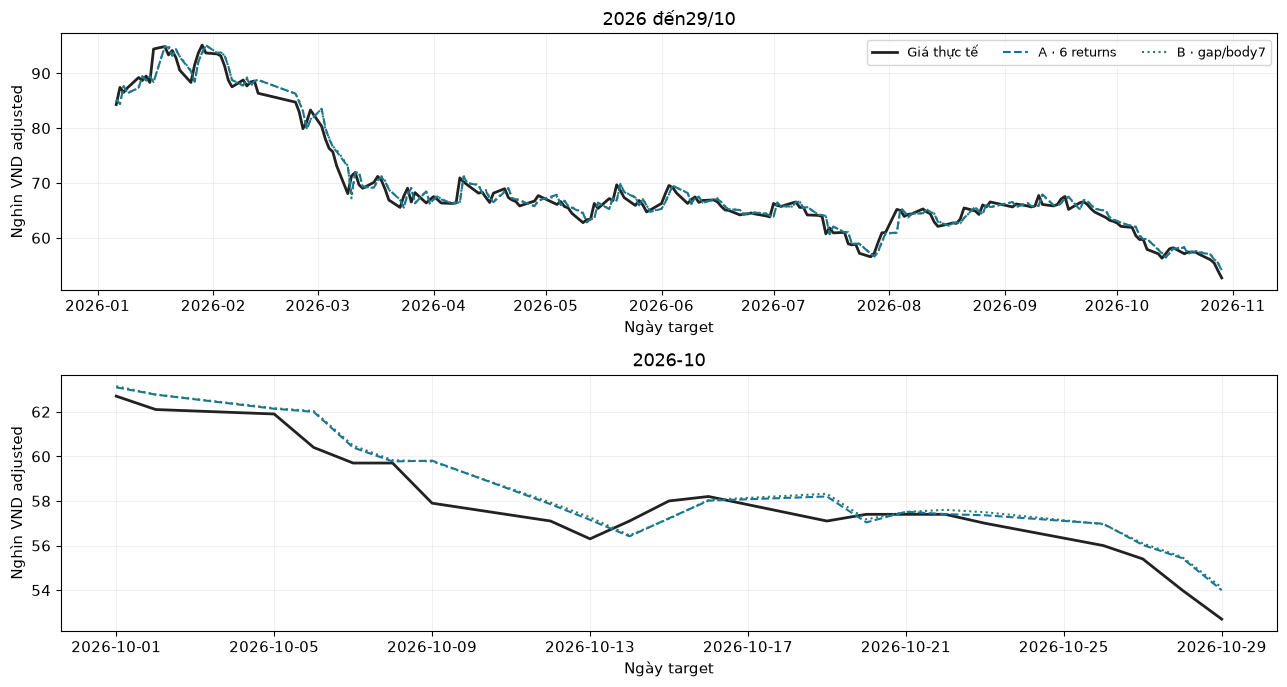

,,n,return_rmse,return_mae,price_mae_adjusted_vnd,price_mape_pct,mse_skill_vs_zero
strategy,case,,,,,,
Ridge_shared,A_returns6,202,0.020,0.015,1082.170,1.543,-0.010
Ridge_recent,A_returns6,202,0.020,0.015,1080.944,1.541,-0.000
Ridge_shared,B_gap_body7,202,0.020,0.016,1092.132,1.558,-0.028
Ridge_recent,B_gap_body7,202,0.020,0.016,1096.734,1.565,-0.029


In [5]:
r=ev[(ev.fold=='eval_2026')&(ev.strategy=='Ridge_recent')]
a=r[r.case=='A_returns6'];b=r[r.case=='B_gap_body7']
fig,axes=plt.subplots(2,1,figsize=(13,7))
for ax,mask,title in [(axes[0],np.ones(len(a),dtype=bool),'2026 đến29/10'),
                      (axes[1],a.Target_Date_1d.dt.strftime('%Y-%m').eq(VIEW_MONTH).to_numpy(),VIEW_MONTH)]:
    ga=a.loc[mask];gb=b.loc[mask]
    ax.plot(ga.Target_Date_1d,ga.Close*np.exp(ga.actual_log_return)/1000,color='#222',lw=2,label='Giá thực tế')
    ax.plot(ga.Target_Date_1d,ga.Close*np.exp(ga.predicted_log_return)/1000,color=COLORS['A_returns6'],ls='--',label='A · 6 returns')
    ax.plot(gb.Target_Date_1d,gb.Close*np.exp(gb.predicted_log_return)/1000,color=COLORS['B_gap_body7'],ls=':',label='B · gap/body7')
    ax.set_title(title);ax.set_ylabel('Nghìn VND adjusted');ax.set_xlabel('Ngày target')
axes[0].legend(ncol=3,fontsize=9);show('04_actual_predicted_price')
table(metrics[(metrics.year==2026)&metrics.strategy.str.startswith('Ridge')].set_index(['strategy','case'])[['n','return_rmse','return_mae','price_mae_adjusted_vnd','price_mape_pct','mse_skill_vs_zero']])

## 5. Classifier / “chưa đủ tín hiệu”: đọc accuracy cùng coverage
Sigmoid và margin mỗi case chọn bằng các phase cũ như nhau. Raw comparison giữ cùng threshold0.5 để thấy ảnh hưởng feature. Accuracy trên mọi calls gồm actual0 là sai; không so với Hit nonzero mà bỏ qua mẫu số.

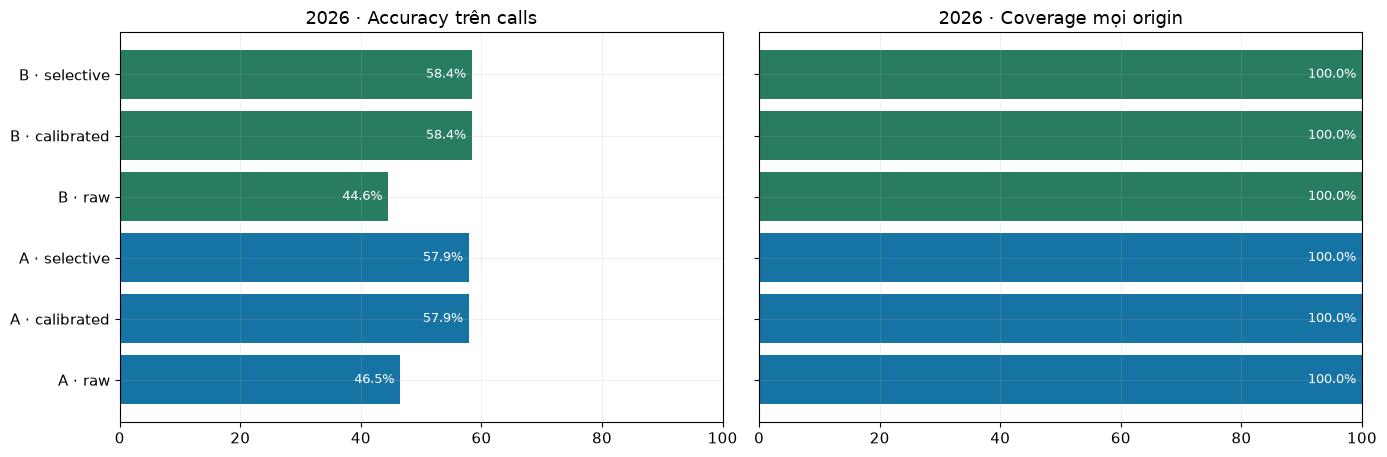

In [6]:
v=metrics[(metrics.year==2026)&metrics.strategy.str.startswith('Logistic')].copy()
v['label']=v.case.str[:1]+' · '+v.strategy.str.replace('Logistic_','',regex=False)
fig,axes=plt.subplots(1,2,figsize=(14,4.7),sharey=True)
for ax,col,title in [(axes[0],'called_accuracy_all_pct','Accuracy trên calls'),(axes[1],'coverage_pct','Coverage mọi origin')]:
    values=v[col].to_numpy();ax.barh(range(len(v)),values,color=[COLORS[x] for x in v.case]);ax.set_yticks(range(len(v)),v.label)
    ax.set_xlim(0,100);ax.set_title('2026 · '+title)
    for i,value in enumerate(values):
        if np.isfinite(value):ax.text(max(2,value-1),i,f'{value:.1f}%',ha='right',va='center',fontsize=9,color='white' if value>20 else 'black')
show('05_classifier_coverage')
table(v.set_index(['case','strategy'])[['n','calls_n','abstain_n','hit_nonzero_called_pct','balanced_called_nonzero_pct','up_coverage_pct','down_coverage_pct']])
table(thresholds.set_index(['fold','case'])[['margin','reason']])

## 6. Xác suất từng phiên và cohort tháng6–10
Xem raw và sigmoid riêng. Chấm actual tăng/giảm tại1/0; actual0 đặt dấu x ở0.5 chỉ để hiển thị, không phải nhãn xác suất0.5. Đường xác suất không phải đường giá. Bảng104 phiên giữ đúng cohort Notebook06; không chuyển CI full2026 cho subset.

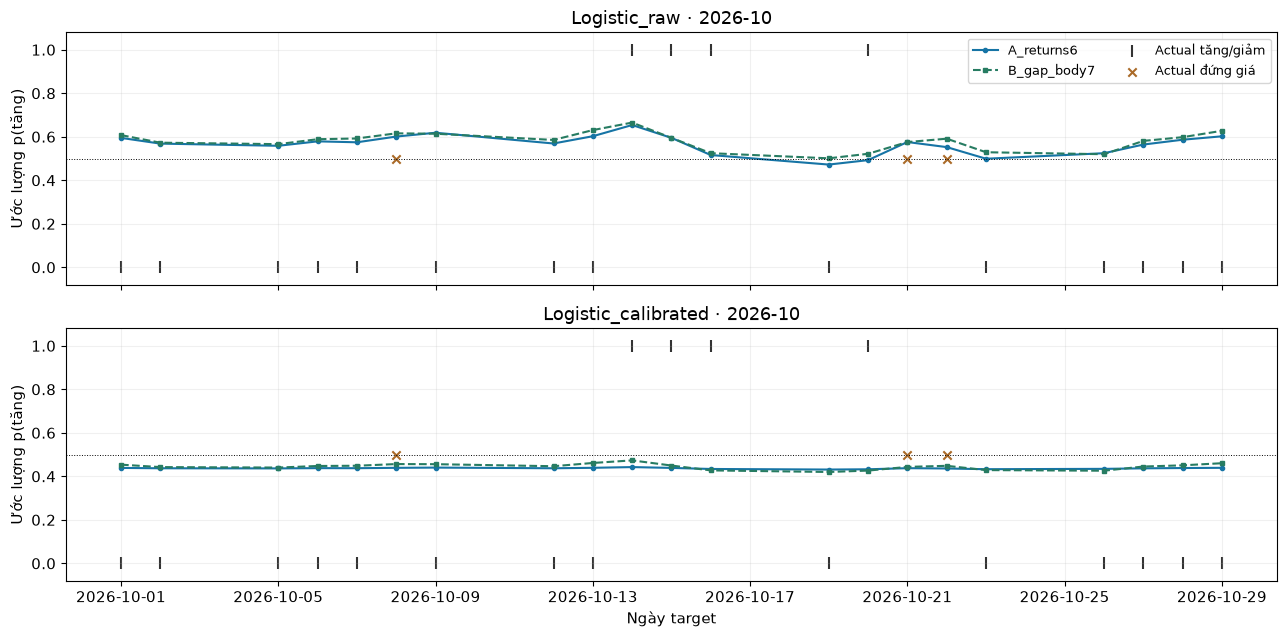

,,n,calls_n,return_rmse,price_mae_adjusted_vnd,hit_nonzero_called_pct,balanced_called_nonzero_pct,coverage_pct
strategy,case,,,,,,,
Logistic_calibrated,A_returns6,104,104,—,—,60.606,50.000,100.000
Logistic_raw,A_returns6,104,104,—,—,43.434,49.295,100.000
Logistic_selective,A_returns6,104,104,—,—,60.606,50.000,100.000
Ridge_recent,A_returns6,104,104,0.017,781.619,50.505,55.128,100.000
Ridge_shared,A_returns6,104,104,0.017,783.692,46.465,51.346,100.000
Logistic_calibrated,B_gap_body7,104,104,—,—,60.606,50.000,100.000
Logistic_raw,B_gap_body7,104,104,—,—,42.424,48.462,100.000
Logistic_selective,B_gap_body7,104,104,—,—,60.606,50.000,100.000
Ridge_recent,B_gap_body7,104,104,0.017,791.786,44.444,49.679,100.000


In [7]:
month=ev[(ev.fold=='eval_2026')&(ev.Target_Date_1d.dt.strftime('%Y-%m')==VIEW_MONTH)]
fig,axes=plt.subplots(2,1,figsize=(13,6.5),sharex=True,sharey=True)
for ax,strategy in zip(axes,['Logistic_raw','Logistic_calibrated']):
    for case in COLORS:
        g=month[(month.case==case)&(month.strategy==strategy)]
        ax.plot(g.Target_Date_1d,g.probability_up,'o-' if case=='A_returns6' else 's--',ms=3,color=COLORS[case],label=case)
    y=np.sign(g.actual_log_return.to_numpy());truth=np.where(y>0,1,np.where(y<0,0,.5));nz=y!=0
    ax.scatter(g.loc[nz,'Target_Date_1d'],truth[nz],color='#333',marker='|',s=70,label='Actual tăng/giảm')
    ax.scatter(g.loc[~nz,'Target_Date_1d'],truth[~nz],color='#aa6a28',marker='x',label='Actual đứng giá')
    ax.axhline(.5,color='black',ls=':',lw=.7);ax.set_ylim(-.08,1.08);ax.set_title(strategy+' · '+VIEW_MONTH);ax.set_ylabel('Ước lượng p(tăng)')
axes[0].legend(fontsize=9,ncol=2);axes[-1].set_xlabel('Ngày target');show('06_daily_probabilities')
table(june_oct.set_index(['strategy','case'])[['n','calls_n','return_rmse','price_mae_adjusted_vnd','hit_nonzero_called_pct','balanced_called_nonzero_pct','coverage_pct']])

## Kết luận và nguồn
Không chốt bằng một tháng hoặc chỉ nhìn đường giá. Đọc A/B trên cùng ngày, validation-selected evaluation, độ lớn thay đổi và CI. Cải thiện direction không tự có nghĩa cải thiện sai số giá; selective phải đọc thêm `same_selected_days.csv`.

Lượt này, B chưa cải thiện ổn định: Logistic raw chỉ tăng mean-fold balanced khoảng 0,09 điểm %, Ridge RMSE trung bình cao hơn. Lựa chọn feature bằng validation cũng không tự bảo đảm evaluation tốt hơn. B selective/fold2023 giữ 136/248 phiên (54,84%) và Hit nonzero 41,46%; coverage tối thiểu60% là điều kiện trên validation, không phải cam kết trên evaluation. Không retune margin dựa vào đoạn đã chấm.

Nguồn cùng study: `REPORT.md`, `DECISION.md`, `protocol.json`, `manifest.json`, `verification.json`, `feature_label_snapshot.csv.gz`, các CSV metrics/predictions/paired_effects. Source/package versions/input hashes lưu trước fit. Case A khớp forecasts đã công bố của study direction trước; model và schema canonical không đổi. Weights nghiên cứu bị gitignore, không cần để xem notebook.

Chỉ nghiên cứu FPT. Không tải nguồn mới, không đổi horizon, không sửa API/Streamlit hoặc promote. Các giai đoạn đã xem, cần các phiên mới để kiểm chứng forward. Không commit/push.